# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Fio Octriyanti
- **Email:** ds284b6x0623@student.devacademy.id
- **ID Dicoding:** FIO OCTRIYANTI



## Menentukan Pertanyaan Bisnis

Analisis ini menggunakan E-Commerce Public Dataset dari Olist. Fokus analisis adalah tren transaksi dan performa pengiriman untuk mendukung evaluasi operasional e-commerce.

**Pertanyaan 1 — Tren transaksi bulanan**

Bagaimana perubahan jumlah pesanan unik dan total nilai produk per bulan selama periode September 2016–Oktober 2018, serta pada bulan mana masing-masing metrik mencapai nilai tertinggi dan terendah?

**Pertanyaan 2 — Ketepatan pengiriman dan ulasan pelanggan**

Selama periode September 2016–Oktober 2018, bagaimana perbedaan rata-rata skor ulasan antara pesanan yang terlambat dan pesanan yang tiba tepat waktu atau lebih cepat, serta negara bagian mana yang memiliki tingkat keterlambatan tertinggi di antara wilayah dengan minimal 100 pesanan yang memiliki data pengiriman lengkap?

**Tujuan analisis**

1. Mengidentifikasi perubahan volume pesanan dan nilai produk untuk membantu perencanaan kapasitas operasional.
2. Membandingkan skor ulasan berdasarkan status pengiriman.
3. Mengidentifikasi wilayah yang perlu dievaluasi lebih lanjut berdasarkan tingkat keterlambatan dan jumlah observasi.

Pertanyaan tersebut dijawab menggunakan agregasi data, visualisasi, dan interpretasi hasil eksplorasi. Analisis bersifat deskriptif sehingga perbedaan skor ulasan tidak langsung dianggap sebagai bukti hubungan sebab-akibat.


**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perubahan jumlah pesanan dan total nilai produk per bulan sepanjang periode data 2016–2018, dan bulan mana yang perlu diprioritaskan untuk perencanaan promosi?
- **Pertanyaan 2:** Bagaimana keterlambatan pengiriman berkaitan dengan skor ulasan pelanggan, dan negara bagian mana yang perlu diprioritaskan untuk perbaikan logistik?


## Import Semua Packages/Library yang Digunakan

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)


## Data Wrangling

### Gathering Data

#### Load dataset E-Commerce Public Dataset


In [3]:
DATA_DIR = Path("data")
orders = pd.read_csv(DATA_DIR / "orders_dataset.csv", parse_dates=["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"])
items = pd.read_csv(DATA_DIR / "order_items_dataset.csv")
payments = pd.read_csv(DATA_DIR / "order_payments_dataset.csv")
reviews = pd.read_csv(DATA_DIR / "order_reviews_dataset.csv")
customers = pd.read_csv(DATA_DIR / "customers_dataset.csv")

print("orders:", orders.shape)
print("items:", items.shape)
print("payments:", payments.shape)
print("reviews:", reviews.shape)
print("customers:", customers.shape)
orders.head()


orders: (99441, 8)
items: (112650, 7)
payments: (103886, 5)
reviews: (99224, 7)
customers: (99441, 5)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


**Insight:**
- Dataset Olist terdiri dari tabel pesanan, item pesanan, pembayaran, ulasan, dan pelanggan.
- Analisis menggunakan agregasi pada tingkat pesanan agar tabel item/pembayaran/ulasan tidak menggandakan hitungan pesanan.


### Assessing Data

#### Memeriksa kualitas data dan mengidentifikasi masalah


In [4]:
print("Informasi orders:")
orders.info()
print("\nMissing values:")
print(orders.isna().sum().sort_values(ascending=False))
print("\nDuplikasi order_id:", orders["order_id"].duplicated().sum())
print("\nStatus pesanan:")
print(orders["order_status"].value_counts(dropna=False))
print("\nRentang waktu pembelian:", orders["order_purchase_timestamp"].min(), "s.d.", orders["order_purchase_timestamp"].max())


Informasi orders:
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  str           
 5   order_delivered_carrier_date   97658 non-null  str           
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](3), str(5)
memory usage: 16.6 MB

Missing values:
order_delivered_customer_date    2965
order_delivered_carrier_date     1783
order_approved_at                 160
order_id                    

**Steps to Take:**
- Kolom tanggal pengiriman memiliki nilai kosong pada pesanan yang belum terkirim; nilai tersebut tidak diisi secara artifisial dan dikecualikan hanya dari analisis durasi pengiriman.
- Tabel item, pembayaran, dan ulasan dapat memiliki beberapa baris per `order_id`; karena itu data diagregasi per pesanan sebelum digabungkan.
- Baris duplikat dan pesanan tanpa timestamp pembelian dibersihkan pada tahap berikutnya.


**Insight:**
- Missing value pada tanggal pengiriman merupakan kondisi yang masuk akal untuk pesanan yang belum selesai, bukan selalu kesalahan pencatatan.
- Penggabungan tabel tanpa agregasi berisiko menggandakan nilai transaksi dan jumlah pesanan.


### Cleaning Data

#### Membersihkan dan menggabungkan data


In [5]:
# Salin data agar sumber asli tetap terjaga.
orders_clean = orders.drop_duplicates(subset="order_id").copy()
orders_clean = orders_clean.dropna(subset=["order_purchase_timestamp"])
items_clean = items.drop_duplicates().copy()
payments_clean = payments.drop_duplicates().copy()
reviews_clean = reviews.drop_duplicates().copy()
customers_clean = customers.drop_duplicates(subset="customer_id").copy()

item_agg = items_clean.groupby("order_id", as_index=False).agg(
    order_items=("order_item_id", "count"),
    order_value=("price", "sum"),
    freight_value=("freight_value", "sum")
)
payment_agg = payments_clean.groupby("order_id", as_index=False).agg(
    payment_value=("payment_value", "sum"),
    payment_installments=("payment_installments", "max")
)
review_agg = reviews_clean.groupby("order_id", as_index=False).agg(
    review_score=("review_score", "mean")
)

analysis_df = (orders_clean
    .merge(item_agg, on="order_id", how="left")
    .merge(payment_agg, on="order_id", how="left")
    .merge(review_agg, on="order_id", how="left")
    .merge(customers_clean[["customer_id", "customer_state", "customer_city"]], on="customer_id", how="left"))
analysis_df["delivery_days"] = (analysis_df["order_delivered_customer_date"] - analysis_df["order_purchase_timestamp"]).dt.total_seconds() / 86400
analysis_df["delivery_delay_days"] = (analysis_df["order_delivered_customer_date"] - analysis_df["order_estimated_delivery_date"]).dt.total_seconds() / 86400
analysis_df["purchase_month"] = analysis_df["order_purchase_timestamp"].dt.to_period("M").astype(str)
analysis_df["is_late"] = analysis_df["delivery_delay_days"].gt(0).where(analysis_df["delivery_delay_days"].notna())
analysis_df = analysis_df[analysis_df["order_status"].isin(["delivered", "shipped", "invoiced", "processing", "approved", "created"])].copy()

print("Ukuran data analisis:", analysis_df.shape)
print("Duplikasi order_id setelah agregasi:", analysis_df["order_id"].duplicated().sum())
analysis_df.head()


Ukuran data analisis: (98207, 20)
Duplikasi order_id setelah agregasi: 0


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_items,order_value,freight_value,payment_value,payment_installments,review_score,customer_state,customer_city,delivery_days,delivery_delay_days,purchase_month,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1.0,29.99,8.72,38.71,1.0,4.0,SP,sao paulo,8.436574,-7.107488,2017-10,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1.0,118.70,22.76,141.46,1.0,4.0,BA,barreiras,13.782037,-5.355729,2018-07,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1.0,159.90,19.22,179.12,3.0,5.0,GO,vianopolis,9.394213,-17.245498,2018-08,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1.0,45.00,27.20,72.20,1.0,5.0,RN,sao goncalo do amarante,13.208750,-12.980069,2017-11,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1.0,19.90,8.72,28.62,1.0,5.0,SP,santo andre,2.873877,-9.238171,2018-02,False


**Insight:**
- Data dibentuk menjadi satu baris per pesanan; item, pembayaran, dan ulasan diagregasi terlebih dahulu.
- Durasi pengiriman hanya tersedia pada pesanan yang memiliki tanggal pembelian dan tanggal diterima.


## Exploratory Data Analysis (EDA)

### Eksplorasi tren pesanan dan performa pengiriman


In [6]:

# EDA 1: Agregasi bulanan untuk pertanyaan bisnis pertama

monthly = (
    analysis_df.groupby("purchase_month", as_index=False)
    .agg(
        orders=("order_id", "nunique"),
        revenue=("order_value", "sum"),
        avg_review=("review_score", "mean"),
        avg_delivery_days=("delivery_days", "mean"),
        orders_with_delivery_data=("delivery_delay_days", "count"),
        late_rate=(
            "is_late",
            lambda s: s.dropna().astype(float).mean() * 100
        )
    )
    .sort_values("purchase_month")
)

# EDA 2: Agregasi negara bagian untuk pertanyaan bisnis kedua

state_summary = (
    analysis_df.groupby("customer_state", as_index=False)
    .agg(
        orders=("order_id", "nunique"),
        revenue=("order_value", "sum"),
        avg_review=("review_score", "mean"),
        avg_delivery_days=("delivery_days", "mean"),
        orders_with_delivery_data=("delivery_delay_days", "count"),
        late_rate=(
            "is_late",
            lambda s: s.dropna().astype(float).mean() * 100
        )
    )
    .sort_values("orders", ascending=False)
)

# Ringkasan statistik untuk memahami distribusi data

numeric_columns = [
    "order_items",
    "order_value",
    "freight_value",
    "payment_value",
    "review_score",
    "delivery_days",
    "delivery_delay_days"
]

print("=== RINGKASAN STATISTIK NUMERIK ===")
display(analysis_df[numeric_columns].describe().T)

# Hasil yang menjawab pertanyaan bisnis pertama

print("=== AGREGASI BULANAN ===")
display(monthly)

print("10 bulan dengan jumlah pesanan tertinggi:")
display(monthly.nlargest(10, "orders"))

print("10 bulan dengan total nilai produk tertinggi:")
display(monthly.nlargest(10, "revenue"))

# Hasil yang menjawab pertanyaan bisnis kedua

print("=== AGREGASI NEGARA BAGIAN ===")
display(state_summary)

print("10 negara bagian dengan tingkat keterlambatan tertinggi")
print("di antara wilayah dengan minimal 100 pesanan berdata pengiriman:")

priority_states = (
    state_summary[
        state_summary["orders_with_delivery_data"] >= 100
    ]
    .dropna(subset=["late_rate"])
    .sort_values("late_rate", ascending=False)
    .head(10)
)

display(
    priority_states[
        [
            "customer_state",
            "orders_with_delivery_data",
            "avg_review",
            "avg_delivery_days",
            "late_rate"
        ]
    ]
)


=== RINGKASAN STATISTIK NUMERIK ===


,count,mean,std,min,25%,50%,75%,max
order_items,98199.0,1.141570,0.537556,1.000000,1.000000,1.000000,1.000000,21.000000
order_value,98199.0,137.418922,209.306418,0.850000,45.900000,86.900000,149.900000,13440.000000
freight_value,98199.0,22.822292,21.645764,0.000000,13.860000,17.190000,24.050000,1794.960000
payment_value,98206.0,160.266552,219.121818,9.590000,62.000000,105.280000,176.750000,13664.080000
review_score,97473.0,4.116593,1.319830,1.000000,4.000000,5.000000,5.000000,5.000000
delivery_days,96470.0,12.558217,9.546156,0.533414,6.766204,10.217477,15.720182,209.628611
delivery_delay_days,96470.0,-11.178126,10.184354,-146.016123,-16.244065,-11.948102,-6.389815,188.975081


=== AGREGASI BULANAN ===


,purchase_month,orders,revenue,avg_review,avg_delivery_days,orders_with_delivery_data,late_rate
0,2016-09,2,207.86,1.000000,54.813194,1,100.000000
1,2016-10,293,44507.30,3.791667,19.600559,265,1.132075
2,2016-12,1,10.90,5.000000,4.693021,1,0.000000
3,2017-01,787,120098.27,4.093308,12.647044,750,3.066667
4,2017-02,1718,244959.35,4.101874,13.168825,1653,3.206292
5,2017-03,2617,368341.32,4.132217,12.951184,2546,5.577376
6,2017-04,2377,353842.98,4.068644,14.917913,2303,7.859314
7,2017-05,3640,503159.19,4.178591,11.322363,3545,3.610719
8,2017-06,3205,429916.61,4.177146,12.011573,3135,3.859649
9,2017-07,3946,492287.30,4.225475,11.592732,3872,3.434917


10 bulan dengan jumlah pesanan tertinggi:


...

,purchase_month,orders,revenue,avg_review,avg_delivery_days,orders_with_delivery_data,late_rate
13,2017-11,7423,1003862.14,3.949199,15.161132,7288,14.311196
18,2018-04,6919,993592.98,4.170261,11.499241,6798,5.310385
19,2018-05,6833,992871.75,4.210325,11.419029,6749,8.238258
17,2018-03,7168,981051.06,3.764213,16.301410,7003,21.362273
15,2018-01,7187,945456.29,4.068201,14.080563,7069,6.563870
21,2018-07,6233,878044.27,4.289997,8.958636,6156,4.483431
20,2018-06,6145,863265.53,4.287792,9.239216,6096,1.361549
22,2018-08,6421,848860.10,4.288026,7.732780,6351,10.392064
16,2018-02,6625,837895.43,3.860236,16.945138,6555,15.987796
14,2017-12,5620,742183.79,4.040992,15.394919,5513,8.380192


=== AGREGASI NEGARA BAGIAN ===


,customer_state,orders,revenue,avg_review,avg_delivery_days,orders_with_delivery_data,late_rate
25,SP,41127,5163867.22,4.211567,8.761386,40494,5.894700
18,RJ,12698,1811623.42,3.904532,15.309438,12350,13.473684
10,MG,11496,1573508.20,4.164420,12.008666,11354,5.610358
22,RS,5417,742559.78,4.155022,15.300276,5344,7.148204
17,PR,4983,676883.06,4.211015,11.991582,4923,4.996953
23,SC,3600,518578.28,4.098264,14.954783,3546,9.757473
4,BA,3344,507108.83,3.883207,19.335466,3256,14.035627
6,DF,2121,300886.45,4.089810,12.967568,2080,7.067308
7,ES,2018,273532.13,4.053742,15.789307,1995,12.230576
8,GO,1998,287870.46,4.069018,15.606339,1957,8.175779


10 negara bagian dengan tingkat keterlambatan tertinggi
di antara wilayah dengan minimal 100 pesanan berdata pengiriman:


,customer_state,orders_with_delivery_data,avg_review,avg_delivery_days,late_rate
1,AL,397,3.764706,24.543855,23.929471
9,MA,717,3.781806,21.572976,19.665272
16,PI,476,3.934021,19.457098,15.966387
5,CE,1279,3.878903,21.266579,15.324472
24,SE,335,3.837209,21.519788,15.223881
4,BA,3256,3.883207,19.335466,14.035627
18,RJ,12350,3.904532,15.309438,13.473684
26,TO,274,4.111913,17.658063,12.773723
13,PA,946,3.857741,23.772917,12.367865
7,ES,1995,4.053742,15.789307,12.230576


**Insight:**
- Ringkasan bulanan menunjukkan pola permintaan dari waktu ke waktu sehingga dapat digunakan untuk merencanakan kapasitas operasional dan promosi.
- Ringkasan per negara bagian memungkinkan perbandingan volume pesanan, rating, durasi pengiriman, dan tingkat keterlambatan.


## Visualization & Explanatory Analysis


### Pertanyaan Bisnis 1 — Tren Transaksi Bulanan

Bagaimana perubahan jumlah pesanan unik dan total nilai produk per bulan selama September 2016–Oktober 2018, serta pada bulan mana masing-masing metrik mencapai nilai tertinggi dan terendah?


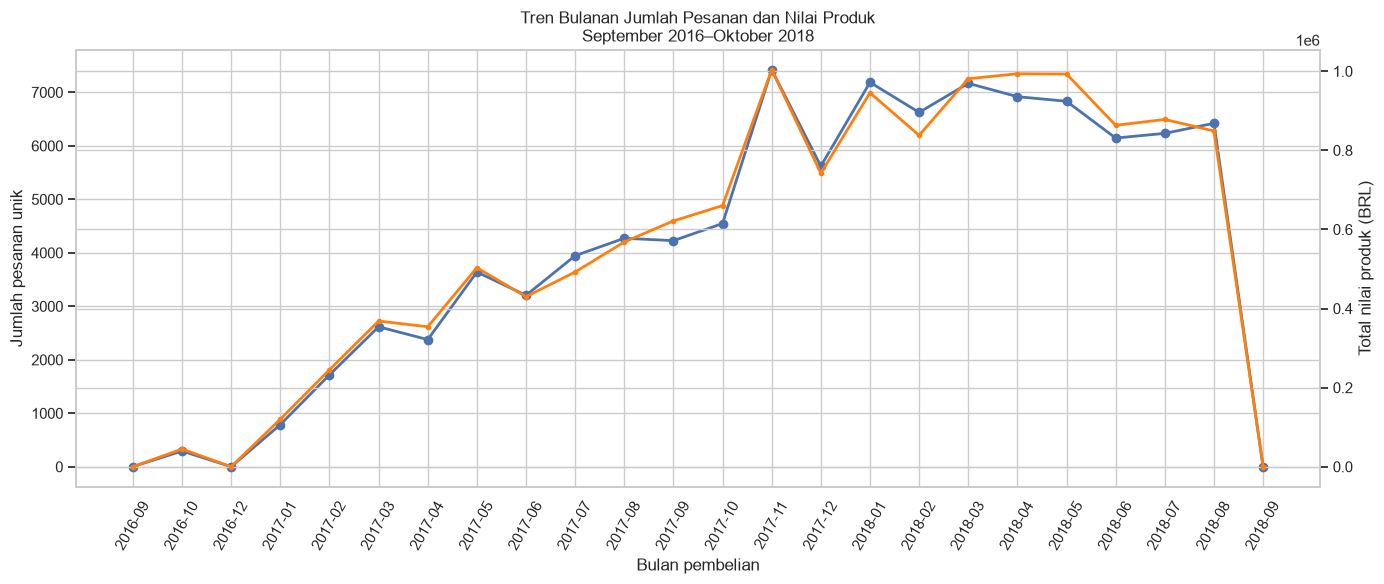

=== EXPLANATORY ANALYSIS: PERTANYAAN 1 ===
Bulan dengan jumlah pesanan tertinggi: 2017-11 (7,423 pesanan).
Bulan dengan jumlah pesanan terendah: 2016-12 (1 pesanan).
Bulan dengan nilai produk tertinggi: 2017-11 (BRL 1,003,862.14).
Bulan dengan nilai produk terendah: 2016-12 (BRL 10.90).

Interpretasi: puncak jumlah pesanan dan puncak nilai produk perlu dievaluasi secara terpisah. Perbedaan waktu terjadinya kedua puncak dapat menjadi dasar evaluasi perencanaan operasional dan promosi.


In [10]:

# Visualisasi pertanyaan bisnis 1:
# Tren jumlah pesanan unik dan total nilai produk per bulan

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(
    monthly["purchase_month"],
    monthly["orders"],
    marker="o",
    linewidth=2,
    label="Jumlah pesanan"
)
ax1.set_xlabel("Bulan pembelian")
ax1.set_ylabel("Jumlah pesanan unik")
ax1.tick_params(axis="x", rotation=60)

ax2 = ax1.twinx()
ax2.plot(
    monthly["purchase_month"],
    monthly["revenue"],
    color="tab:orange",
    marker=".",
    linewidth=2,
    label="Total nilai produk"
)
ax2.set_ylabel("Total nilai produk (BRL)")

ax1.set_title(
    "Tren Bulanan Jumlah Pesanan dan Nilai Produk\n"
    "September 2016–Oktober 2018"
)

fig.tight_layout()
plt.show()

# Mengidentifikasi bulan tertinggi dan terendah
peak_orders = monthly.loc[monthly["orders"].idxmax()]
lowest_orders = monthly.loc[monthly["orders"].idxmin()]

peak_revenue = monthly.loc[monthly["revenue"].idxmax()]
lowest_revenue = monthly.loc[monthly["revenue"].idxmin()]

print("=== EXPLANATORY ANALYSIS: PERTANYAAN 1 ===")

print(
    f"Bulan dengan jumlah pesanan tertinggi: "
    f"{peak_orders['purchase_month']} "
    f"({int(peak_orders['orders']):,} pesanan)."
)

print(
    f"Bulan dengan jumlah pesanan terendah: "
    f"{lowest_orders['purchase_month']} "
    f"({int(lowest_orders['orders']):,} pesanan)."
)

print(
    f"Bulan dengan nilai produk tertinggi: "
    f"{peak_revenue['purchase_month']} "
    f"(BRL {peak_revenue['revenue']:,.2f})."
)

print(
    f"Bulan dengan nilai produk terendah: "
    f"{lowest_revenue['purchase_month']} "
    f"(BRL {lowest_revenue['revenue']:,.2f})."
)

print(
    "\nInterpretasi: puncak jumlah pesanan dan puncak nilai produk "
    "perlu dievaluasi secara terpisah. Perbedaan waktu terjadinya "
    "kedua puncak dapat menjadi dasar evaluasi perencanaan operasional "
    "dan promosi."
)



### Pertanyaan Bisnis 2 — Ketepatan Pengiriman dan Ulasan Pelanggan

Selama September 2016–Oktober 2018, bagaimana perbedaan rata-rata skor ulasan antara pesanan yang terlambat dan pesanan yang tiba tepat waktu atau lebih cepat, serta negara bagian mana yang memiliki tingkat keterlambatan tertinggi di antara wilayah dengan minimal 100 pesanan yang memiliki data pengiriman lengkap?


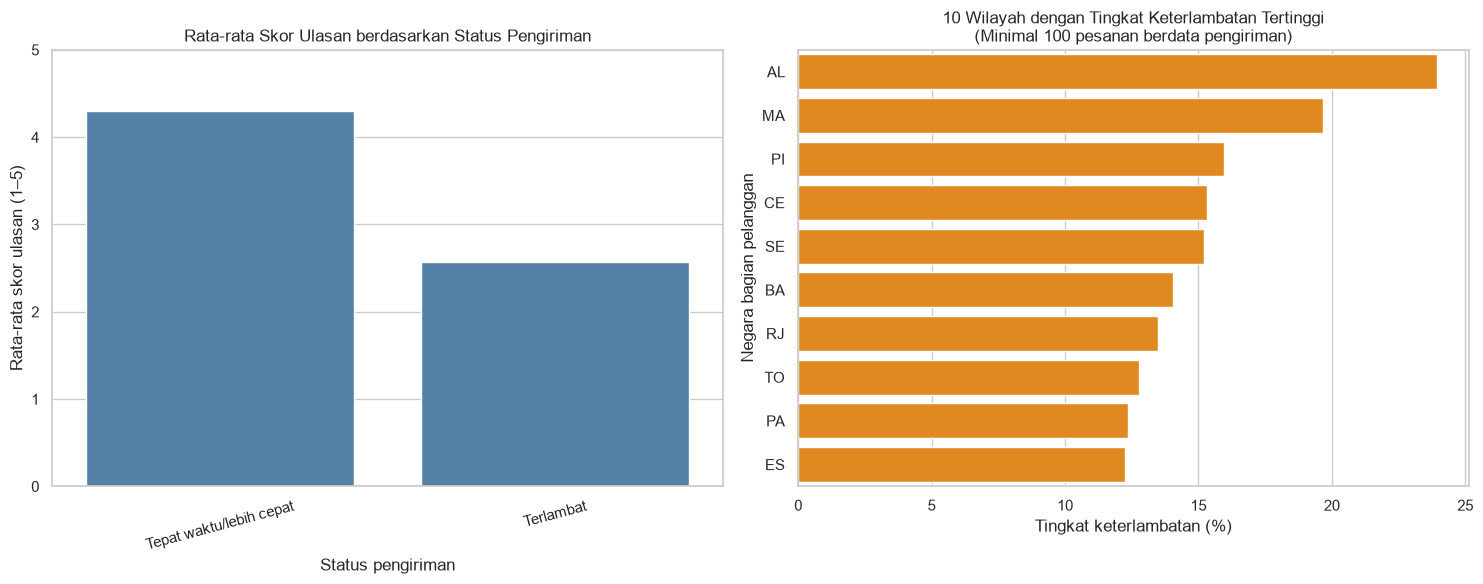

=== HASIL PERBANDINGAN SKOR ULASAN ===


,delivery_status,avg_review,orders
0,Tepat waktu/lebih cepat,4.294292,88163
1,Terlambat,2.566506,7661


=== WILAYAH PRIORITAS LOGISTIK ===


,customer_state,orders_with_delivery_data,avg_review,avg_delivery_days,late_rate
1,AL,397,3.764706,24.543855,23.929471
9,MA,717,3.781806,21.572976,19.665272
16,PI,476,3.934021,19.457098,15.966387
5,CE,1279,3.878903,21.266579,15.324472
24,SE,335,3.837209,21.519788,15.223881
4,BA,3256,3.883207,19.335466,14.035627
18,RJ,12350,3.904532,15.309438,13.473684
26,TO,274,4.111913,17.658063,12.773723
13,PA,946,3.857741,23.772917,12.367865
7,ES,1995,4.053742,15.789307,12.230576



=== EXPLANATORY ANALYSIS: PERTANYAAN 2 ===
Rata-rata skor ulasan pesanan terlambat: 2.57/5.
Rata-rata skor ulasan pesanan tepat waktu/lebih cepat: 4.29/5.
Selisih absolut rata-rata skor ulasan: 1.73 poin.
Wilayah dengan tingkat keterlambatan tertinggi dalam kelompok wilayah yang memenuhi batas sampel: AL (23.93%).
Jumlah pesanan berdata pengiriman pada wilayah tersebut: 397.


In [11]:

# Persiapan data perbandingan status pengiriman dan ulasan

delivery_review = analysis_df.dropna(
    subset=["delivery_delay_days", "review_score"]
).copy()

delivery_review["delivery_status"] = np.where(
    delivery_review["delivery_delay_days"] > 0,
    "Terlambat",
    "Tepat waktu/lebih cepat"
)

# Agregasi skor ulasan berdasarkan status pengiriman

review_by_delivery = (
    delivery_review.groupby("delivery_status", as_index=False)
    .agg(
        avg_review=("review_score", "mean"),
        orders=("order_id", "nunique")
    )
)

# Wilayah dengan setidaknya 100 pesanan berdata pengiriman

priority_states = (
    state_summary[
        state_summary["orders_with_delivery_data"] >= 100
    ]
    .dropna(subset=["late_rate"])
    .sort_values("late_rate", ascending=False)
    .head(10)
)

# Visualisasi dua bagian pertanyaan bisnis kedua

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    data=review_by_delivery,
    x="delivery_status",
    y="avg_review",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title(
    "Rata-rata Skor Ulasan berdasarkan Status Pengiriman"
)
axes[0].set_xlabel("Status pengiriman")
axes[0].set_ylabel("Rata-rata skor ulasan (1–5)")
axes[0].set_ylim(0, 5)
axes[0].tick_params(axis="x", rotation=15)

sns.barplot(
    data=priority_states,
    y="customer_state",
    x="late_rate",
    ax=axes[1],
    color="darkorange"
)

axes[1].set_title(
    "10 Wilayah dengan Tingkat Keterlambatan Tertinggi\n"
    "(Minimal 100 pesanan berdata pengiriman)"
)
axes[1].set_xlabel("Tingkat keterlambatan (%)")
axes[1].set_ylabel("Negara bagian pelanggan")

plt.tight_layout()
plt.show()

print("=== HASIL PERBANDINGAN SKOR ULASAN ===")
display(review_by_delivery)

print("=== WILAYAH PRIORITAS LOGISTIK ===")
display(
    priority_states[
        [
            "customer_state",
            "orders_with_delivery_data",
            "avg_review",
            "avg_delivery_days",
            "late_rate"
        ]
    ]
)

print("\n=== EXPLANATORY ANALYSIS: PERTANYAAN 2 ===")

scores = review_by_delivery.set_index("delivery_status")["avg_review"]

late_score = scores.get("Terlambat", np.nan)
on_time_score = scores.get("Tepat waktu/lebih cepat", np.nan)

if pd.notna(late_score) and pd.notna(on_time_score):
    print(f"Rata-rata skor ulasan pesanan terlambat: {late_score:.2f}/5.")
    print(
        f"Rata-rata skor ulasan pesanan tepat waktu/lebih cepat: "
        f"{on_time_score:.2f}/5."
    )
    print(
        f"Selisih absolut rata-rata skor ulasan: "
        f"{abs(late_score - on_time_score):.2f} poin."
    )
else:
    print(
        "Perbandingan belum dapat dilakukan karena data salah satu "
        "kelompok status pengiriman tidak tersedia."
    )

if not priority_states.empty:
    worst_state = priority_states.iloc[0]

    print(
        f"Wilayah dengan tingkat keterlambatan tertinggi dalam "
        f"kelompok wilayah yang memenuhi batas sampel: "
        f"{worst_state['customer_state']} "
        f"({worst_state['late_rate']:.2f}%)."
    )
    print(
        f"Jumlah pesanan berdata pengiriman pada wilayah tersebut: "
        f"{int(worst_state['orders_with_delivery_data']):,}."
    )
else:
    print(
        "Tidak ada wilayah yang memenuhi batas minimal 100 pesanan "
        "berdata pengiriman."
    )



### Insight EDA

**1. Tren transaksi bulanan**

Agregasi bulanan digunakan untuk mengamati perubahan jumlah pesanan unik dan total nilai produk sepanjang periode observasi. Bulan dengan volume pesanan tertinggi dan bulan dengan nilai produk tertinggi perlu diperiksa secara terpisah karena kedua metrik tersebut tidak selalu mencapai puncak pada waktu yang sama.

**2. Performa pengiriman**

Agregasi per negara bagian membantu membandingkan tingkat keterlambatan, rata-rata durasi pengiriman, dan rata-rata skor ulasan. Penggunaan jumlah pesanan dengan data pengiriman lengkap sebagai batas sampel membantu menghindari pemeringkatan wilayah yang hanya didasarkan pada sedikit observasi.

**3. Kualitas dan kelengkapan data**

Nilai tanggal pengiriman yang kosong tidak boleh langsung dianggap sebagai keterlambatan. Pesanan tanpa data pengiriman yang memadai dikecualikan dari perhitungan tingkat keterlambatan. Demikian pula, rata-rata skor ulasan hanya dihitung dari pesanan yang memiliki data ulasan.

**4. Penggunaan hasil agregasi**

Hasil agregasi menjadi dasar untuk visualisasi dan explanatory analysis. Interpretasi akhir harus merujuk pada nilai yang benar-benar muncul dari output, bukan asumsi mengenai bulan atau wilayah dengan performa terbaik maupun terburuk.


## Analisis Lanjutan (Opsional)

In [9]:
# Analisis lanjutan: segmentasi pelanggan berbasis RFM (manual, bukan machine learning)
rfm_base = analysis_df.dropna(subset=["order_purchase_timestamp"]).copy()
customer_rfm = rfm_base.groupby("customer_unique_id" if "customer_unique_id" in rfm_base.columns else "customer_id", as_index=False).agg(
    last_purchase=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("order_value", "sum")
)
reference_date = rfm_base["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
customer_rfm["recency_days"] = (reference_date - customer_rfm["last_purchase"]).dt.days
customer_rfm["R_segment"] = pd.qcut(customer_rfm["recency_days"].rank(method="first"), 4, labels=[4, 3, 2, 1]).astype(int)
customer_rfm["F_segment"] = pd.qcut(customer_rfm["frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
customer_rfm["M_segment"] = pd.qcut(customer_rfm["monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
customer_rfm["RFM_score"] = customer_rfm[["R_segment", "F_segment", "M_segment"]].astype(int).astype(str).agg("".join, axis=1)
customer_rfm["RFM_group"] = np.select(
    [customer_rfm["R_segment"] >= 3, customer_rfm["F_segment"] >= 3, customer_rfm["M_segment"] >= 3],
    ["Pelanggan terbaru", "Sering bertransaksi", "Belanja bernilai tinggi"], default="Perlu diaktifkan kembali")
display(customer_rfm.groupby("RFM_group", as_index=False).agg(customers=("RFM_score", "size"), avg_recency=("recency_days", "mean"), avg_frequency=("frequency", "mean"), avg_monetary=("monetary", "mean")))


,RFM_group,customers,avg_recency,avg_frequency,avg_monetary
0,Belanja bernilai tinggi,12102,372.945629,1.0,229.917595
1,Pelanggan terbaru,49104,118.816369,1.0,137.522378
2,Perlu diaktifkan kembali,12362,372.440301,1.0,46.199418
3,Sering bertransaksi,24639,372.348715,1.0,137.502413



### Insight dan Interpretasi — Pertanyaan Bisnis 2

**1. Hubungan status pengiriman dengan skor ulasan**

Rata-rata skor ulasan kedua kelompok dibandingkan untuk melihat apakah terdapat perbedaan penilaian pelanggan berdasarkan status pengiriman. Besar selisih dan jumlah pesanan masing-masing kelompok perlu diperhatikan sebelum menarik interpretasi.

**2. Identifikasi wilayah prioritas**

Negara bagian diurutkan berdasarkan tingkat keterlambatan, dengan syarat minimal 100 pesanan memiliki data pengiriman yang lengkap. Persentase keterlambatan digunakan bersama jumlah observasi agar hasil pemeringkatan lebih informatif.

**3. Implikasi bisnis**

Wilayah dengan tingkat keterlambatan relatif tinggi dapat menjadi kandidat untuk evaluasi SLA kurir, waktu pemrosesan pesanan, dan koordinasi dengan seller. Namun, analisis ini belum mengidentifikasi penyebab keterlambatan secara langsung.

**Catatan:** Interpretasi akhir harus disesuaikan dengan angka aktual yang muncul pada tabel dan grafik. Perbedaan rata-rata ulasan merupakan hubungan deskriptif, bukan bukti bahwa keterlambatan menjadi satu-satunya penyebab perubahan skor ulasan.



## Conclusion

**Kesimpulan Pertanyaan Bisnis 1 — Tren Transaksi**

Agregasi bulanan digunakan untuk mengevaluasi perubahan jumlah pesanan unik dan total nilai produk selama periode observasi. Bulan dengan jumlah pesanan tertinggi belum tentu sama dengan bulan dengan nilai produk tertinggi. Kedua indikator perlu diperhatikan secara terpisah untuk membantu perencanaan kapasitas operasional dan evaluasi kalender promosi.

**Kesimpulan Pertanyaan Bisnis 2 — Ketepatan Pengiriman dan Ulasan**

Perbandingan rata-rata skor ulasan digunakan untuk mengevaluasi perbedaan penilaian pelanggan antara pesanan terlambat dan pesanan tepat waktu atau lebih cepat. Analisis tingkat keterlambatan per negara bagian membantu mengidentifikasi wilayah yang layak dievaluasi lebih lanjut, khususnya wilayah dengan jumlah observasi memadai.

Kesimpulan akhir mengenai bulan dengan performa tertinggi, selisih skor ulasan, dan wilayah prioritas harus merujuk pada hasil perhitungan yang ditampilkan pada bagian visualisasi dan explanatory analysis.

**Keterbatasan Analisis**

- Analisis bersifat deskriptif dan tidak membuktikan hubungan sebab-akibat.
- Pesanan tanpa informasi pengiriman yang memadai tidak digunakan dalam perhitungan keterlambatan.
- Rata-rata skor ulasan hanya merepresentasikan pesanan yang memiliki data ulasan.
- Hasil analisis berlaku untuk periode dan cakupan data yang digunakan, bukan otomatis untuk periode di luar pengamatan.



## Rekomendasi Action Item

1. **Perencanaan kapasitas operasional:** Gunakan tren bulanan jumlah pesanan untuk memperkirakan kebutuhan layanan pelanggan dan koordinasi seller pada periode dengan volume transaksi tinggi.

2. **Evaluasi nilai transaksi:** Bandingkan bulan dengan nilai produk tertinggi dan terendah untuk menentukan periode yang perlu dianalisis lebih lanjut sebelum menyusun strategi promosi.

3. **Evaluasi performa logistik:** Tinjau proses pengiriman pada wilayah dengan tingkat keterlambatan tinggi dan jumlah pesanan yang memadai. Pemeriksaan dapat mencakup SLA kurir, waktu pemrosesan pesanan, dan koordinasi dengan seller.

4. **Pemantauan pengalaman pelanggan:** Pantau skor ulasan dan tingkat keterlambatan secara berkala untuk mengevaluasi apakah perubahan proses logistik diikuti perubahan pada indikator layanan.

5. **Evaluasi berkala:** Ulangi agregasi bulanan setelah tersedia data periode berikutnya agar tren operasional dapat dibandingkan secara konsisten.
